# HRRR-AK forecast-hour mosaics: snow-model forcing and PPSA observations

Compare the selected native-grid forecast options: **f123, f567, f6to11, and f6to29**, for the available parts of WY2024 and WY2025. This is a point comparison at the native grid cell nearest PPSA, not a domain average. Change the point coordinates below to explore another cell; PPSA validation applies only to the PPSA point.

The processed series already choose a forecast for each valid time. We preserve that choice rather than creating new forecast mosaics. `valid_time` is checked against `time`, and `step` gives the actual forecast lead; initialization time is `valid_time − step`. **Do not infer the schedule from the filename alone:** WY2025’s `f678` file contains leads 5–7. The audit below flags it. `f678` is excluded from every plot and comparison statistic; it remains in the inventory for provenance. `f6to11` uses the 00/06/12/18 UTC cycles and `f6to29` the 00 UTC cycle in these files, while f567 draws on three-hourly cycles.

All dates and daily bins are **UTC**. Missing hours remain missing. Statistics use identical complete-case timestamps across the options being scored. Different file coverage and missing observations must not be interpreted as forecast skill.

## Settings

The full-coverage plots show daily means (precipitation sums) only for complete 24-hour days. Hourly storm plots retain the original hourly detail. Colors and windows are editable. Default storm windows are shared by all options. Eight fields cover the main snow-model forcing variables. Native wind components have not been rotated to earth coordinates, so direction is shown as grid-relative and is not validated against station wind.

In [1]:
from pathlib import Path
import sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'small_juneau_domain/_forecast_comparison.py').is_file())
sys.path.insert(0,str(ROOT/'small_juneau_domain'))
import _forecast_comparison as fc
importlib.reload(fc)
DATA_ROOT=fc.DATA_ROOT
STATION_CSV=fc.OBS_CSV
LATITUDE, LONGITUDE, SITE_ELEVATION = 58.262, -134.517, 670.
LAPSE_RATE = .006  # K/m; optional temperature correction only.
PERIODS = ('WY2024','WY2025')
OPTIONS = fc.OPTIONS
COLORS = {'f123':'tab:gray','f567':'tab:blue',
          'f6to11':'tab:orange','f6to29':'tab:purple'}
STYLES = {o:dict(color=COLORS[o],linewidth=1.25,
                linestyle='-') for o in OPTIONS}
VARIABLES = ('TA','RH','PSUM','VW','DW','ISWR','ILWR','PS')
ZOOM_WINDOWS = {'WY2024':('2023-12-20','2024-01-01'),
                'WY2025':('2024-12-20','2025-01-01')}
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

In [2]:
frames,inventory,excluded_versions=fc.load_all(DATA_ROOT,latitude=LATITUDE,longitude=LONGITUDE,
    site_elevation=SITE_ELEVATION,lapse_rate=LAPSE_RATE)
observations,observation_audit=fc.load_observations(STATION_CSV)
missing=[(p,o) for p in PERIODS for o in OPTIONS if (p,o) not in frames]
if missing: raise FileNotFoundError(f'Missing forecast options: {missing}')
display(inventory[['period','option','start_UTC','end_UTC','rows','missing_hours',
    'actual_leads_h','initialization_hours_UTC','lead_label_matches']])
display(inventory[['period','option','grid_y','grid_x','grid_latitude','grid_longitude',
    'distance_km','grid_elevation_m','site_elevation_m','TA_correction_C']].round(3))
display(excluded_versions)
display(pd.Series(observation_audit,name='PPSA observation preparation'))
flagged=inventory.loc[~inventory.lead_label_matches]
for row in flagged.itertuples():
    display(Markdown(f'**Label mismatch:** {row.period} `{row.option}` actually uses forecast hours **{row.actual_leads_h}**. '
                     'It is retained in the inventory only and excluded from plots and comparison statistics.'))
def option_label(period,option):
    row=inventory.loc[inventory.period.eq(period)&inventory.option.eq(option)].iloc[0]
    return option+(' * (actual f567)' if not row.lead_label_matches else '')
def date_axis(ax):
    locator=mdates.AutoDateLocator(minticks=4,maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(alpha=.2)
def legend_handles(period,station=True):
    handles=[Line2D([],[],label=option_label(period,o),**STYLES[o]) for o in OPTIONS]
    if station:handles.append(Line2D([],[],color='black',lw=1.5,label='PPSA observations'))
    return handles

,period,option,start_UTC,end_UTC,rows,missing_hours,actual_leads_h,initialization_hours_UTC,lead_label_matches
0,WY2024,f123,2023-10-01 01:00:00,2024-10-01 00:00:00,8784,0,"1,2,3","0,3,6,9,12,15,18,21",True
1,WY2025,f123,2024-10-01 01:00:00,2025-04-01 00:00:00,4368,0,"1,2,3","0,3,6,9,12,15,18,21",True
2,WY2024,f567,2023-10-01 05:00:00,2024-02-16 04:00:00,3311,1,"5,6,7","0,3,6,9,12,15,18,21",True
3,WY2025,f567,2024-10-01 05:00:00,2025-04-21 04:00:00,4842,6,"5,6,7","0,3,6,9,12,15,18,21",True
4,WY2024,f678,2023-10-01 06:00:00,2024-02-16 05:00:00,3312,0,"6,7,8","0,3,6,9,12,15,18,21",True
5,WY2025,f678,2024-10-01 05:00:00,2025-04-21 04:00:00,4810,38,"5,6,7","0,3,6,9,12,15,18,21",False
6,WY2024,f6to11,2023-10-01 06:00:00,2024-02-16 05:00:00,3309,3,"6,7,8,9,10,11","0,6,12,18",True
7,WY2025,f6to11,2024-10-01 06:00:00,2025-04-21 05:00:00,4801,47,"6,7,8,9,10,11","0,6,12,18",True
8,WY2024,f6to29,2023-10-01 06:00:00,2024-02-16 05:00:00,3311,1,"6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22...",0,True
9,WY2025,f6to29,2024-10-01 06:00:00,2025-04-21 05:00:00,4822,26,"6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22...",0,True


,period,option,grid_y,grid_x,grid_latitude,grid_longitude,distance_km,grid_elevation_m,site_elevation_m,TA_correction_C
0,WY2024,f123,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
1,WY2025,f123,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
2,WY2024,f567,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
3,WY2025,f567,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
4,WY2024,f678,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
5,WY2025,f678,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
6,WY2024,f6to11,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
7,WY2025,f6to11,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
8,WY2024,f6to29,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507
9,WY2025,f6to29,7,8,58.269,-134.526,0.923,585.551,670.0,-0.507


,option,period,selected,excluded_older_version,selected_point_values_match
0,f567,WY2025,/hdd/snow_hydrology/hrrrak/small_juneau_domain...,/hdd/snow_hydrology/hrrrak/small_juneau_domain...,True


source                   /hdd/snow_hydrology/met_station/ppsa2/PPSA2.20...
duplicates_kept_first                                                   11
precipitation            Difference of consecutive valid hourly cumulat...
timestamps               UTC; gauge increment is for the hour ending at...
Name: PPSA observation preparation, dtype: object

**Label mismatch:** WY2025 `f678` actually uses forecast hours **5,6,7**. It is retained in the inventory only and excluded from plots and comparison statistics.

## Which lead supplies each hour?

The first 48 hours of each available period show the stored lead schedule. Gaps interrupt the line. These are valid times, not initialization times. The audit above lists the initialization-cycle hours. The older WY2025 f567 test file is excluded from the main comparison; its extracted point values are checked against the selected later version so the same forecast is not counted twice. Reprojected, cropped, and short test exports are not distinct forecast options.

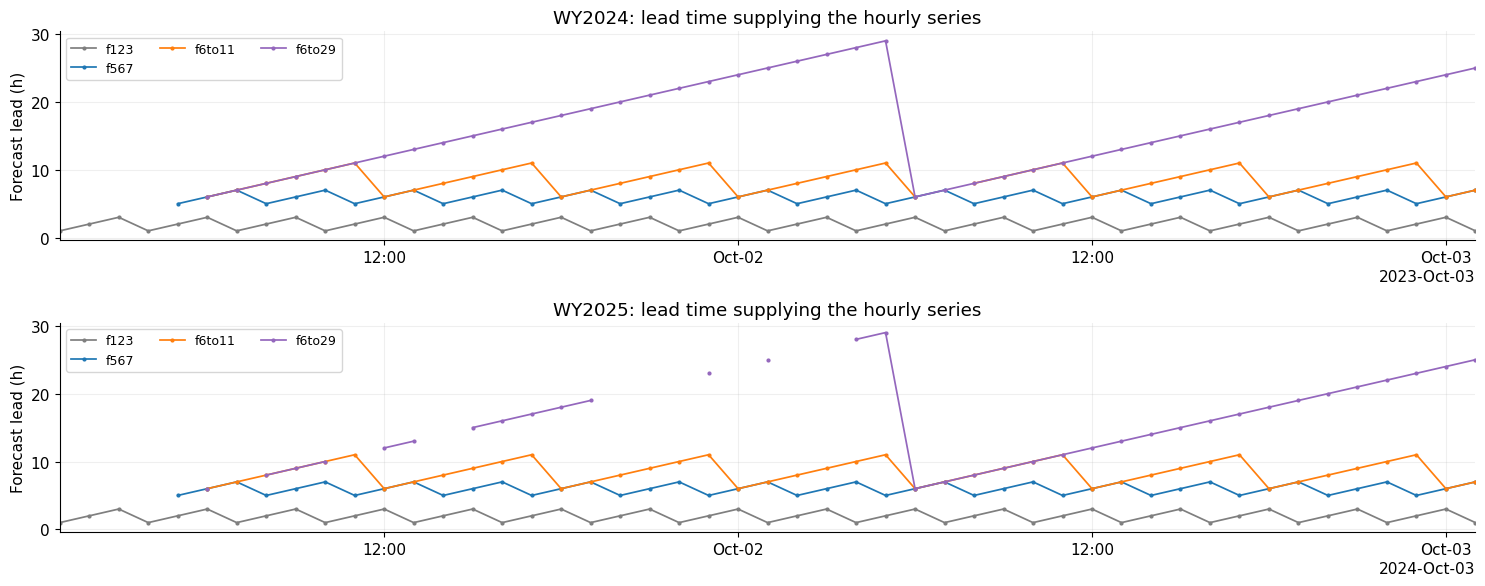

In [3]:
fig,axes=plt.subplots(2,1,figsize=(15,6),sharey=True)
for period,ax in zip(PERIODS,axes):
    start=min(frames[(period,o)].index.min() for o in OPTIONS)
    end=start+pd.Timedelta(hours=48)
    for option in OPTIONS:
        s=frames[(period,option)].lead_h.loc[start:end]
        ax.plot(s.index,s,marker='.',markersize=4,label=option_label(period,option),**STYLES[option])
    ax.set(title=f'{period}: lead time supplying the hourly series',ylabel='Forecast lead (h)',xlim=(start,end))
    date_axis(ax);ax.legend(ncol=3,fontsize=9)
fig.tight_layout();plt.show()

## All forcing variables: available coverage and hourly storms

Daily overview panels retain each option’s available coverage. Black curves show station temperature, RH, and precipitation; there is no station validation for the other variables. Temperature here is **raw HRRR**, without a lapse-rate adjustment. Daily wind direction uses the circular mean, with near-calm hours excluded. Partial days are omitted. Precipitation is the forcing convention **instantaneous PRATE × 3600**, used as an estimated hourly amount; it is not a verified GRIB interval accumulation. `tp` / `precip_total` are deliberately not differenced across forecast-cycle boundaries.

The second figure for each period shows hourly storm detail. Changing `ZOOM_WINDOWS` reveals other storms without reprocessing the original GRIB files.

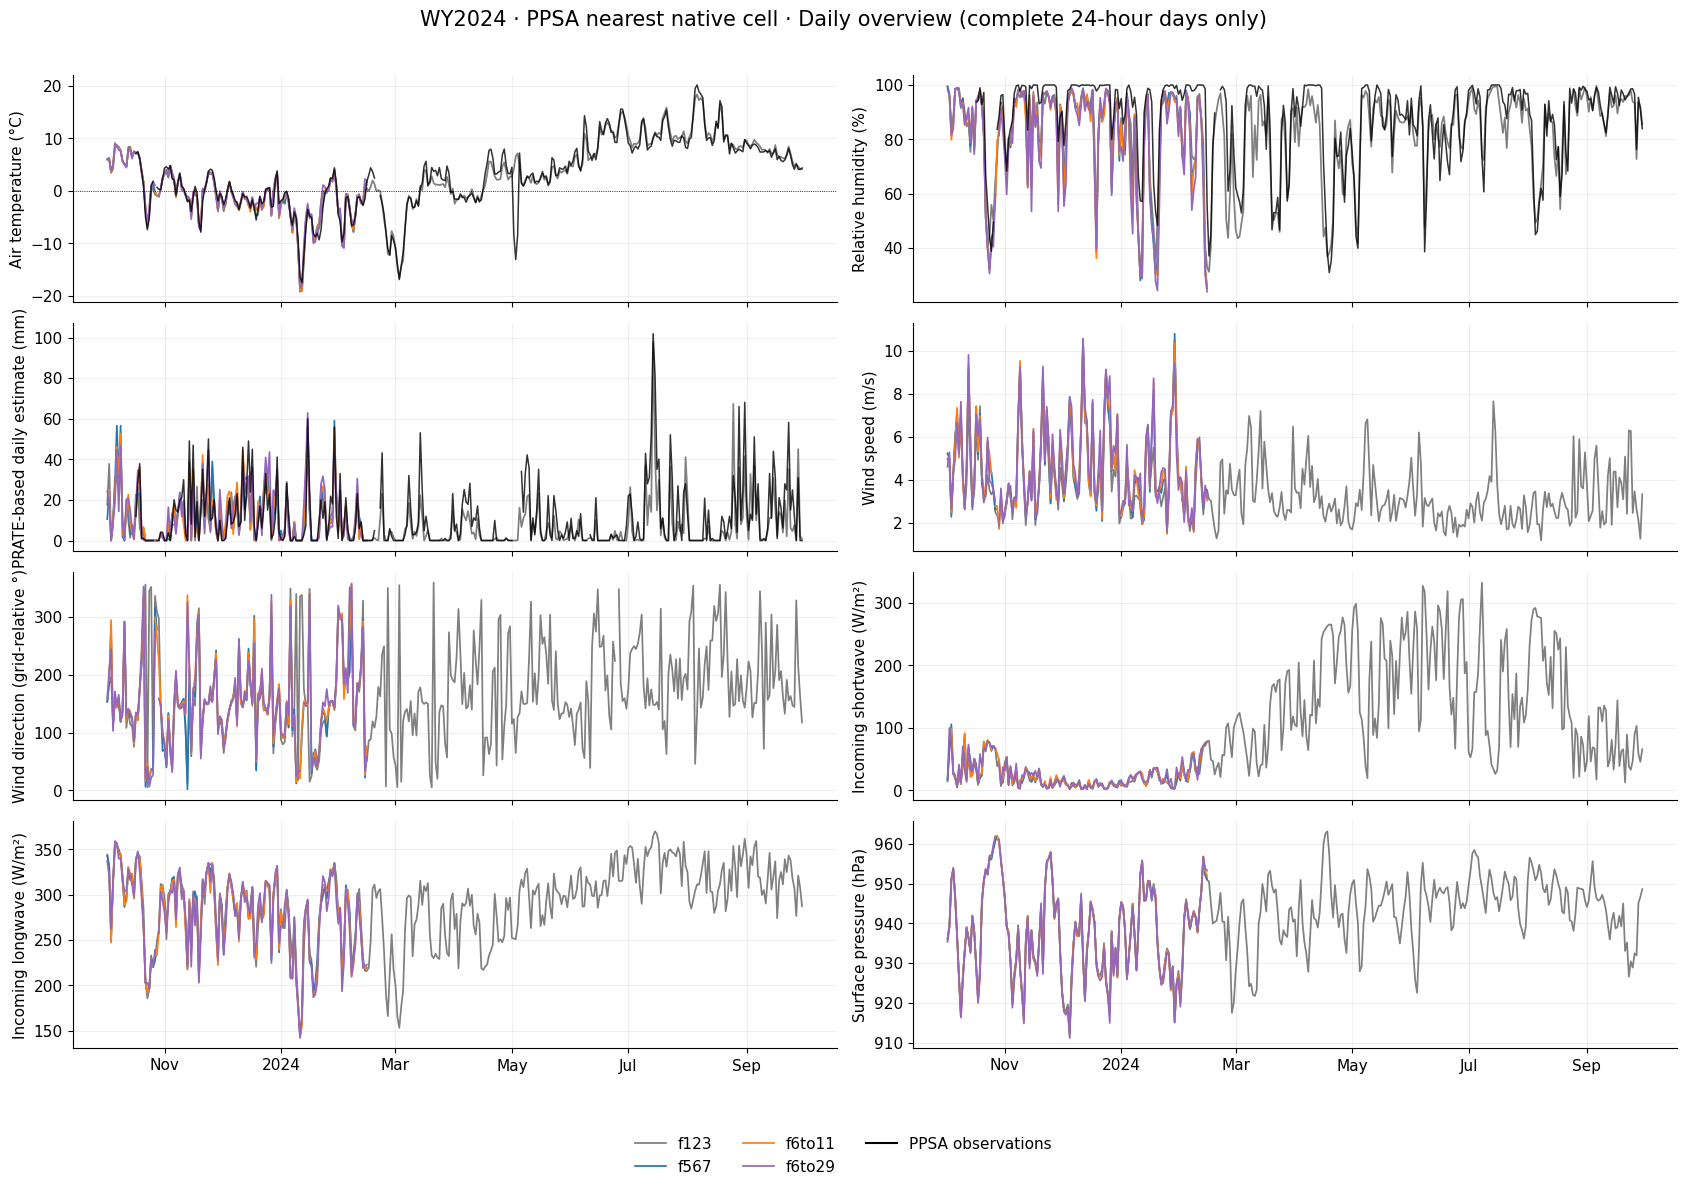

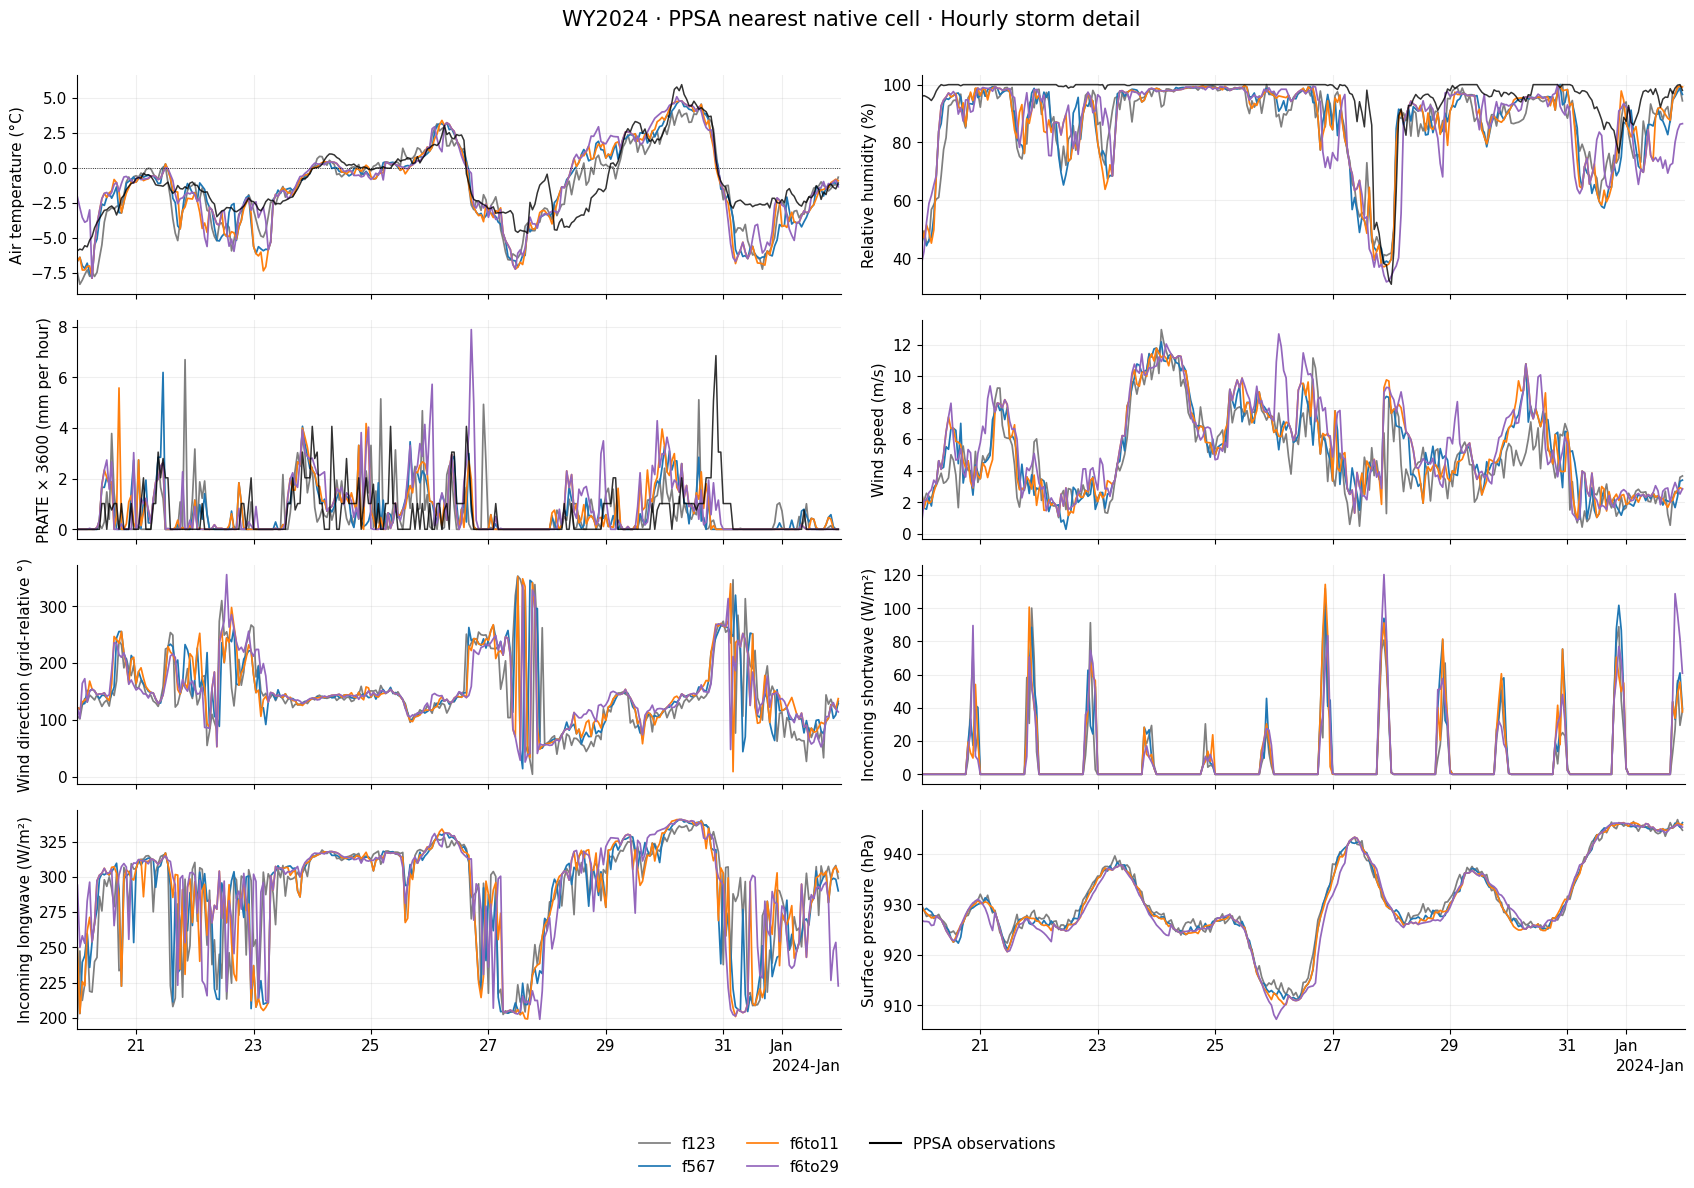

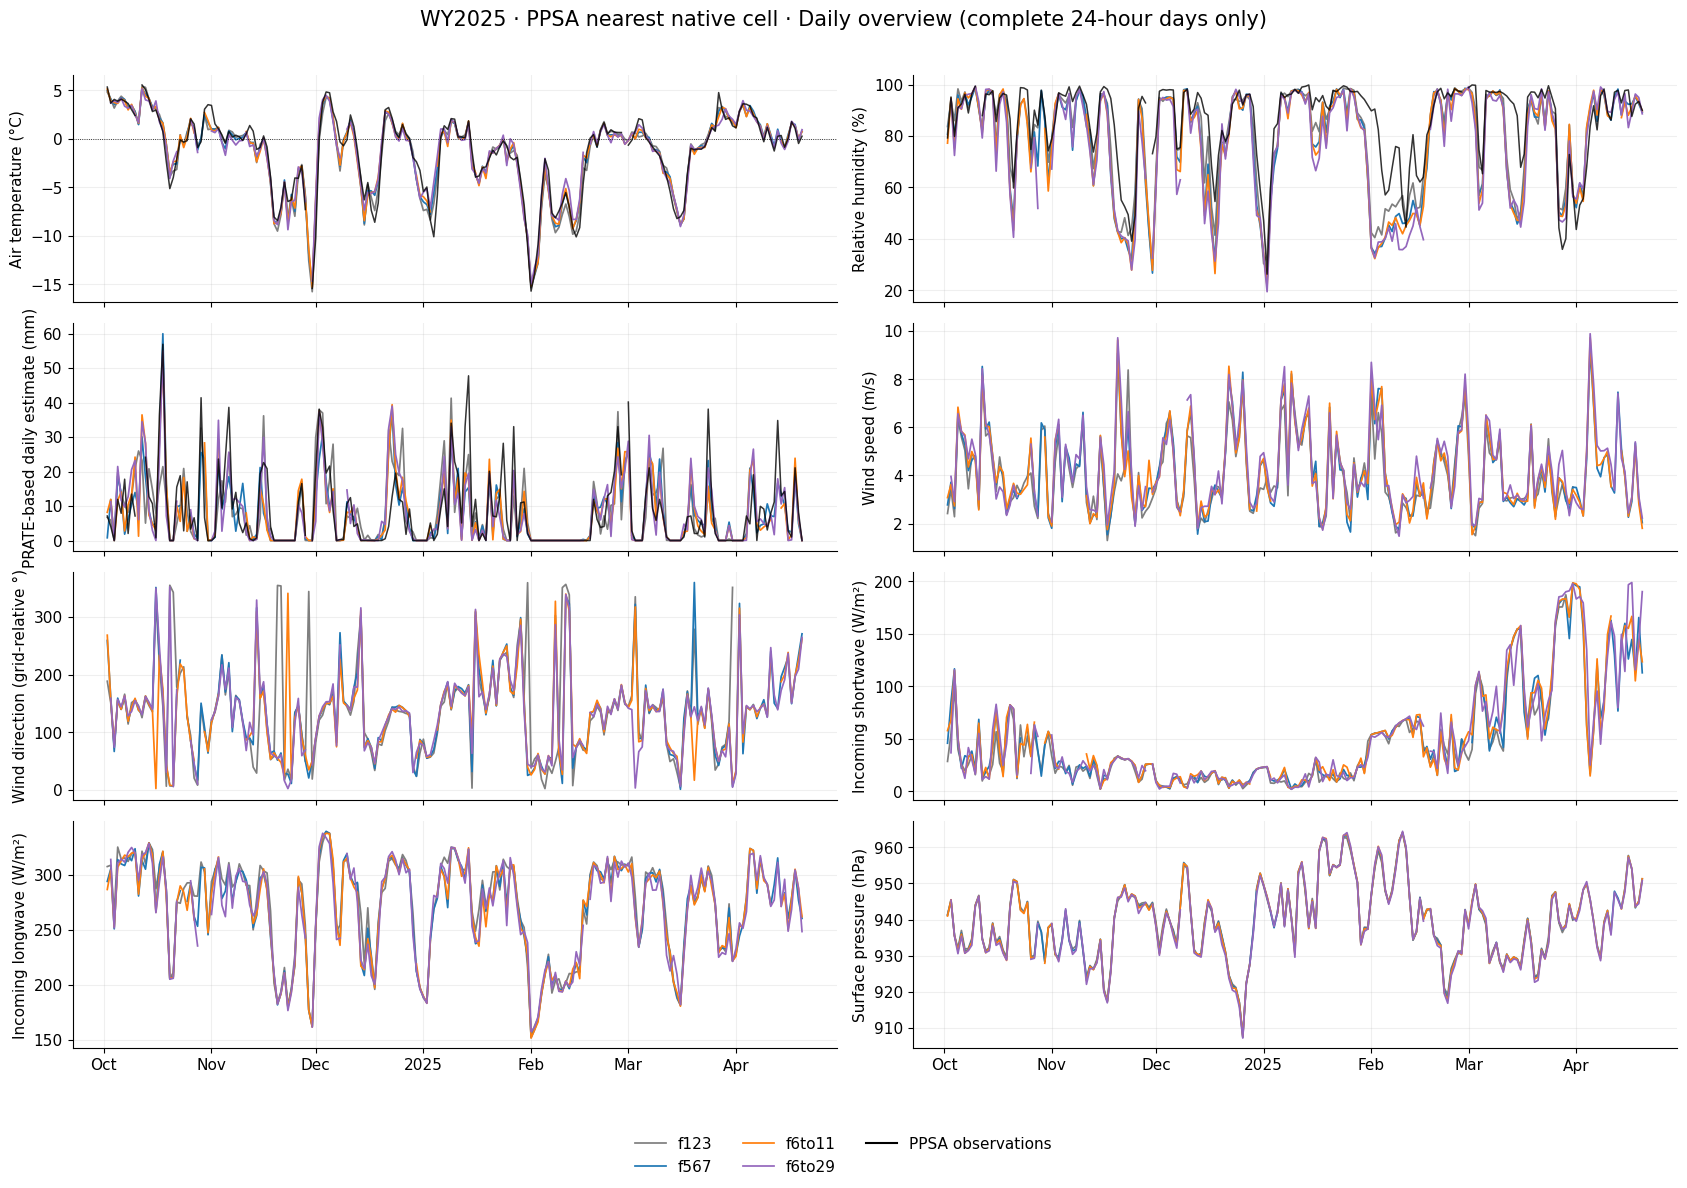

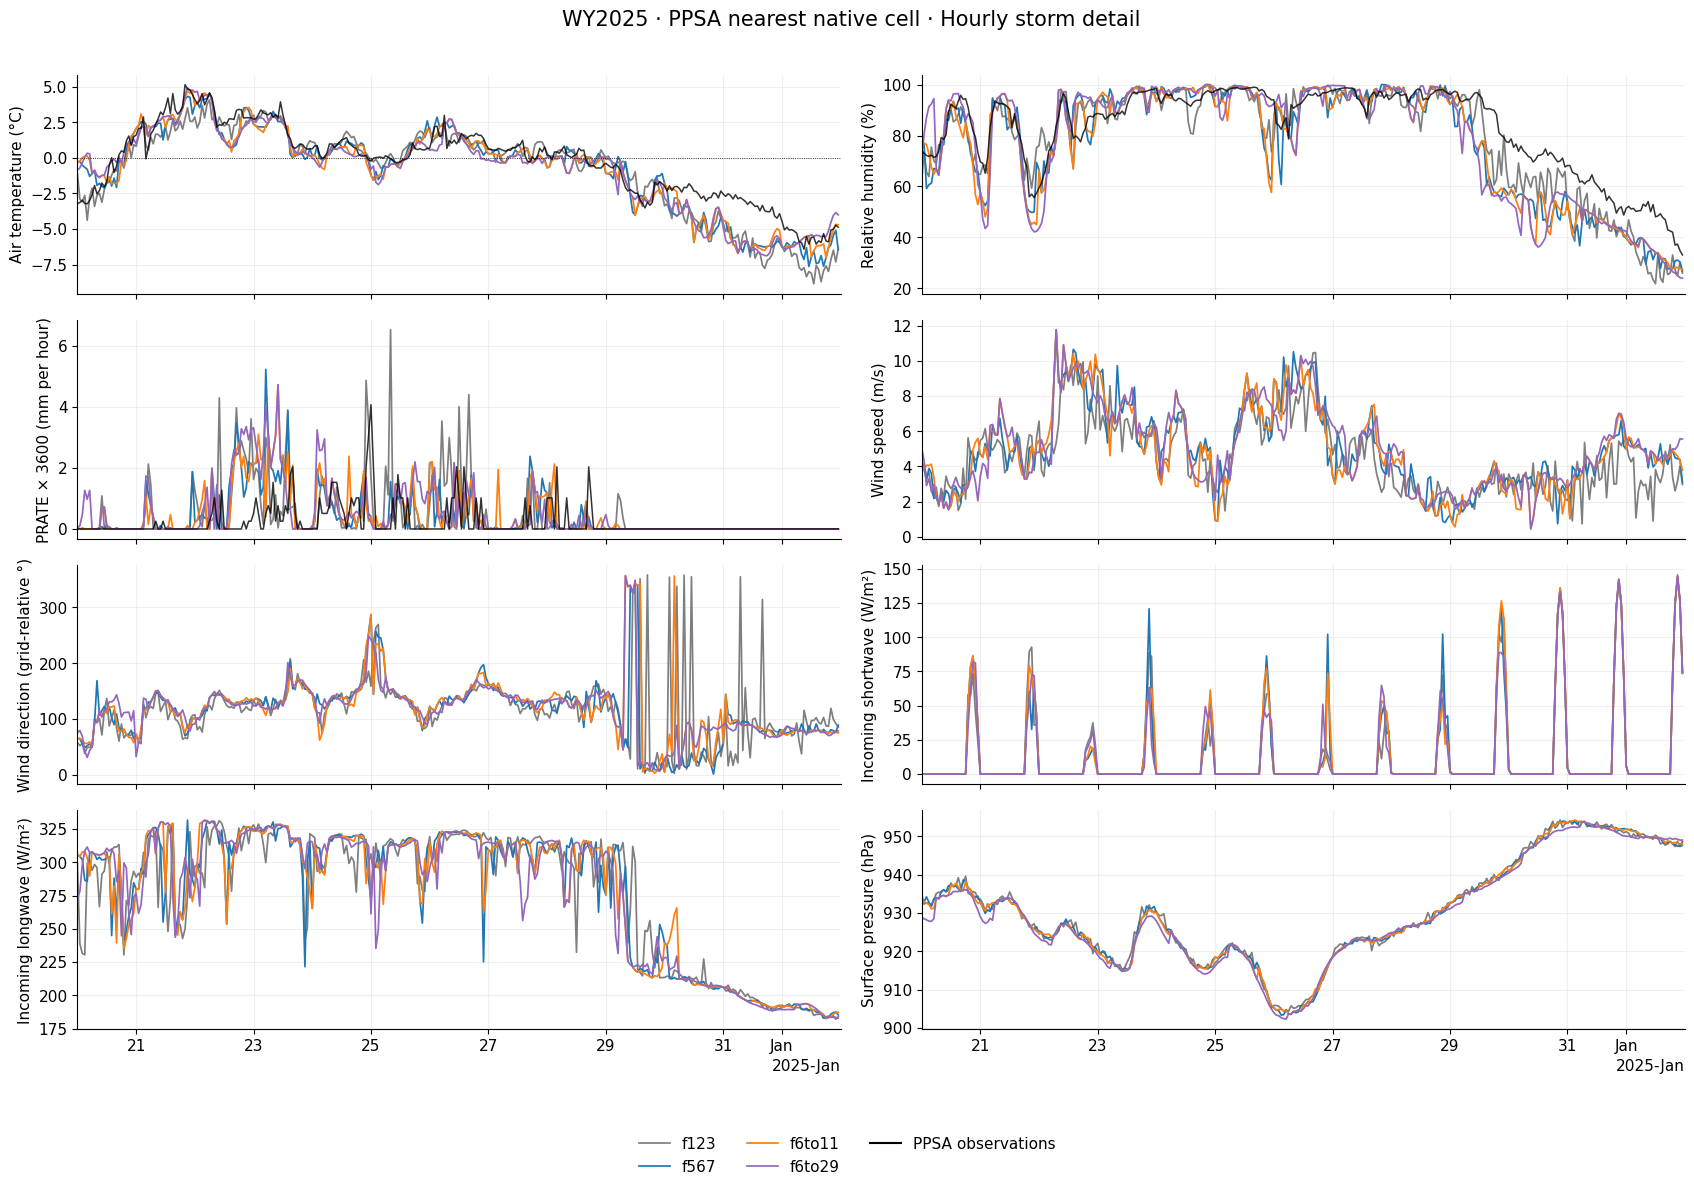

In [4]:
def overview_value(series,variable):
    if variable=='DW':
        radians=np.deg2rad(series)
        sine=fc.strict_daily(np.sin(radians));cosine=fc.strict_daily(np.cos(radians))
        return np.degrees(np.arctan2(sine,cosine))%360
    return fc.strict_daily(series,'sum' if variable=='PSUM' else 'mean')
def forcing_figure(period,window=None):
    fig,axes=plt.subplots(4,2,figsize=(17,12),sharex=True)
    for variable,ax in zip(VARIABLES,axes.flat):
        for option in OPTIONS:
            s=frames[(period,option)][variable]
            s=s.loc[window[0]:window[1]] if window else overview_value(s,variable)
            ax.plot(s.index,s,**STYLES[option])
        if variable in ['TA','RH','PSUM']:
            s=observations[variable]
            if window:s=s.loc[window[0]:window[1]]
            else:
                start=min(frames[(period,o)].index.min() for o in OPTIONS)
                end=max(frames[(period,o)].index.max() for o in OPTIONS)
                s=overview_value(s.loc[start:end],variable)
            ax.plot(s.index,s,color='black',lw=1.1,alpha=.8)
        label=fc.LABELS[variable]
        if not window and variable=='PSUM':label='PRATE-based daily estimate (mm)'
        ax.set_ylabel(label);date_axis(ax)
        if variable=='TA':ax.axhline(0,color='black',lw=.6,ls=':')
        if window:ax.set_xlim(pd.Timestamp(window[0]),pd.Timestamp(window[1])+pd.Timedelta(days=1))
    title='Hourly storm detail' if window else 'Daily overview (complete 24-hour days only)'
    fig.suptitle(f'{period} · PPSA nearest native cell · {title}',fontsize=15)
    fig.legend(handles=legend_handles(period),loc='lower center',ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.08,1,.97));plt.show()
for period in PERIODS:
    forcing_figure(period)
    forcing_figure(period,ZOOM_WINDOWS[period])

## Focus: f6to11 minus f567

This comparison uses just the two focal options, over all their shared valid timestamps (it is not shortened by f123’s coverage). The difference panels summarize daily mean differences, including the mean hourly precipitation difference; each daily point requires 24 paired hours. The table reports hourly bias, MAE, and RMSE for all eight forcing variables. Direction errors use the wrapped −180° to +180° difference. Precipitation totals in the table refer only to the matched hours. These forecast-to-forecast differences measure sensitivity to the mosaic, not observational skill.

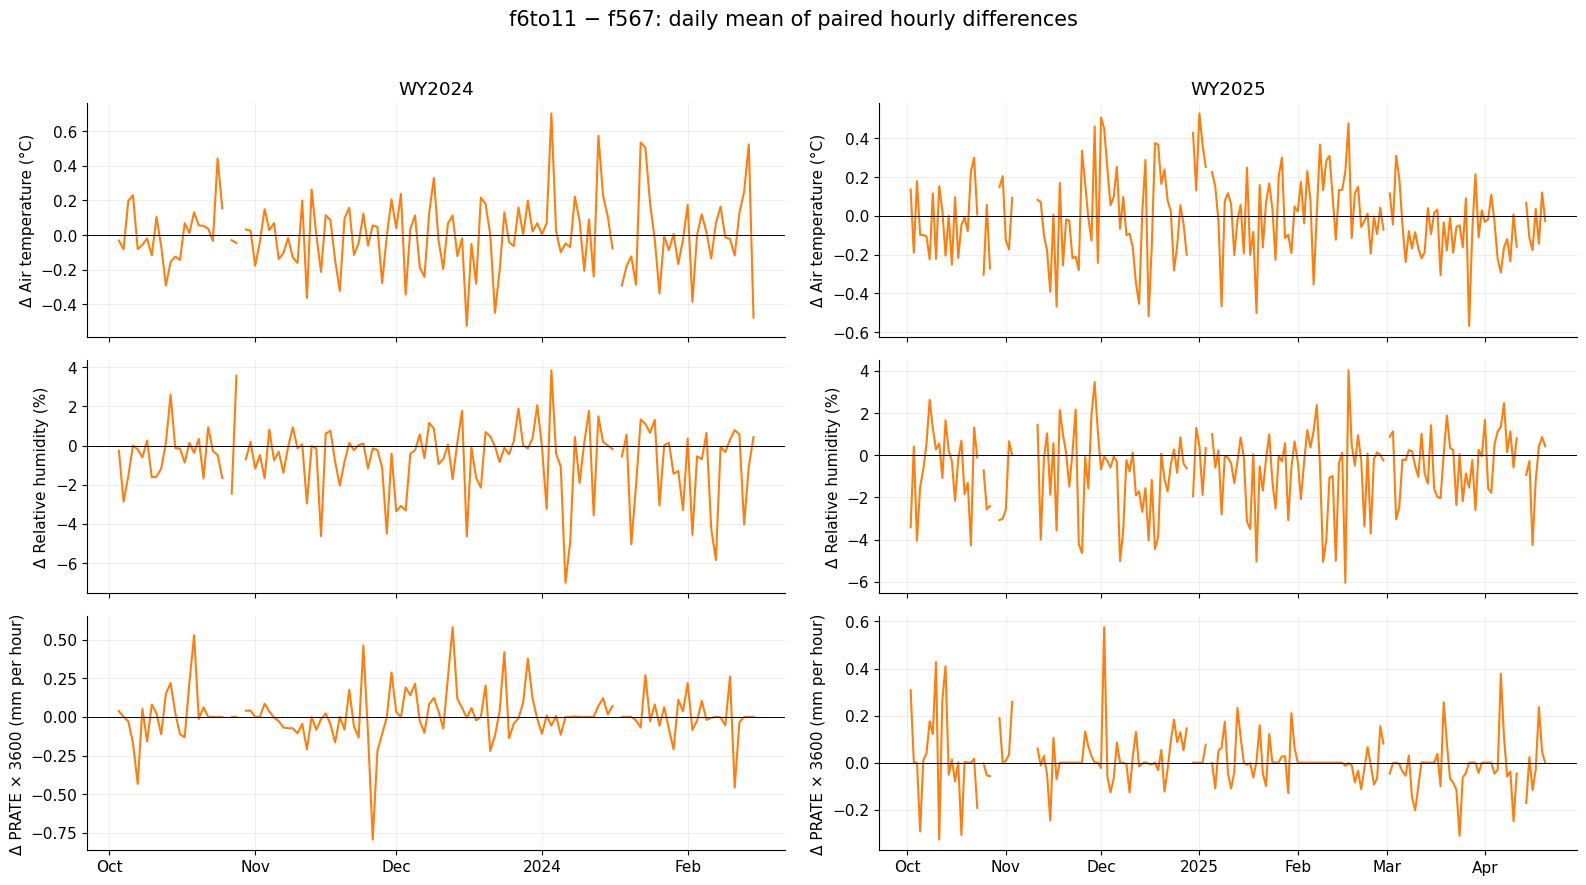

/tmp/ipykernel_552458/1813379565.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  forecast_difference_metrics=pd.concat(pair_rows,ignore_index=True)


,period,variable,n_hours,bias,MAE,RMSE,reference_total_mm,option_total_mm
0,WY2024,TA,3307,0.002,0.309,0.541000,NaN,NaN
1,WY2024,RH,3307,-0.696,2.335,4.537000,NaN,NaN
2,WY2024,PSUM,3307,0.009,0.232,0.676000,1680.552002,1709.640015
3,WY2024,VW,3307,0.049,0.465,0.766000,NaN,NaN
4,WY2024,DW,3307,1.828,11.140,25.103001,NaN,NaN
5,WY2024,ISWR,3307,0.282,3.830,16.014999,NaN,NaN
6,WY2024,ILWR,3307,-1.119,7.168,15.759000,NaN,NaN
7,WY2024,PS,3307,-0.020,0.349,0.542000,NaN,NaN
8,WY2025,TA,4794,-0.012,0.334,0.573000,NaN,NaN
9,WY2025,RH,4794,-0.694,2.642,5.005000,NaN,NaN


In [5]:
pair_rows=[]
fig,axes=plt.subplots(3,2,figsize=(16,9),sharex='col')
for col,period in enumerate(PERIODS):
    for variable in VARIABLES:
        table=fc.common_table(frames,period,variable,options=('f567','f6to11'))
        result=fc.metrics(table,'f567',variable).assign(period=period,variable=variable)
        pair_rows.append(result)
        if variable in ['TA','RH','PSUM']:
            ax=axes[['TA','RH','PSUM'].index(variable),col]
            delta=fc.difference(table.f6to11,table.f567,variable)
            s=fc.strict_daily(delta)
            ax.plot(s.index,s,color=COLORS['f6to11'])
            ax.axhline(0,color='black',lw=.7);date_axis(ax)
            ax.set_ylabel('Δ '+fc.LABELS[variable])
            if variable=='TA':ax.set_title(period)
fig.suptitle('f6to11 − f567: daily mean of paired hourly differences',fontsize=15)
fig.tight_layout(rect=(0,0,1,.96));plt.show()
forecast_difference_metrics=pd.concat(pair_rows,ignore_index=True)
display(forecast_difference_metrics[['period','variable','n_hours','bias','MAE','RMSE',
    'reference_total_mm','option_total_mm']].round(3))

## PPSA validation on common observed hours

Raw PPSA CSV units are Celsius, percent, and millimeters. Temperature and RH use exact hourly observations, without interpolation. Hourly gauge precipitation is the difference of consecutive valid hourly cumulative readings; missing endpoints, gaps, resets (negative changes), and increments above 40 mm remain missing. This avoids the older cleaning workflow’s conversion of some missing increments to zero. A gauge increment ends at its timestamp; the model PRATE estimate is instantaneous, so storm-hour disagreement can also reflect this timing/quantity mismatch. Gauge undercatch, snow and wind effects, and point-versus-grid differences remain relevant.

Within each period and variable, **all four selected forecast options are scored on the same observed hours**. Raw and lapse-rate-adjusted temperature use the same observation variable. The optional correction is `−0.006 × (670 − grid elevation)` °C and is shown separately; RH is unchanged. Metrics are point-validation diagnostics for these partial windows, not a general ranking of forecast lead quality.

/tmp/ipykernel_552458/1704144377.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  station_metrics=pd.concat(station_rows,ignore_index=True)


,period,variable,option,n_hours,bias,MAE,RMSE,reference_total_mm,option_total_mm
0,WY2024,TA,f123,2934,-0.255,0.943,1.314,NaN,NaN
1,WY2024,TA,f567,2934,-0.067,1.027,1.442,NaN,NaN
2,WY2024,TA,f6to11,2934,-0.059,1.073,1.516,NaN,NaN
3,WY2024,TA,f6to29,2934,0.036,1.185,1.643,NaN,NaN
4,WY2024,TA_lapse,f123,2934,-0.762,1.120,1.497,NaN,NaN
5,WY2024,TA_lapse,f567,2934,-0.574,1.175,1.550,NaN,NaN
6,WY2024,TA_lapse,f6to11,2934,-0.566,1.225,1.617,NaN,NaN
7,WY2024,TA_lapse,f6to29,2934,-0.470,1.313,1.709,NaN,NaN
8,WY2024,RH,f123,2934,-8.938,10.309,15.505,NaN,NaN
9,WY2024,RH,f567,2934,-10.756,11.603,17.741,NaN,NaN


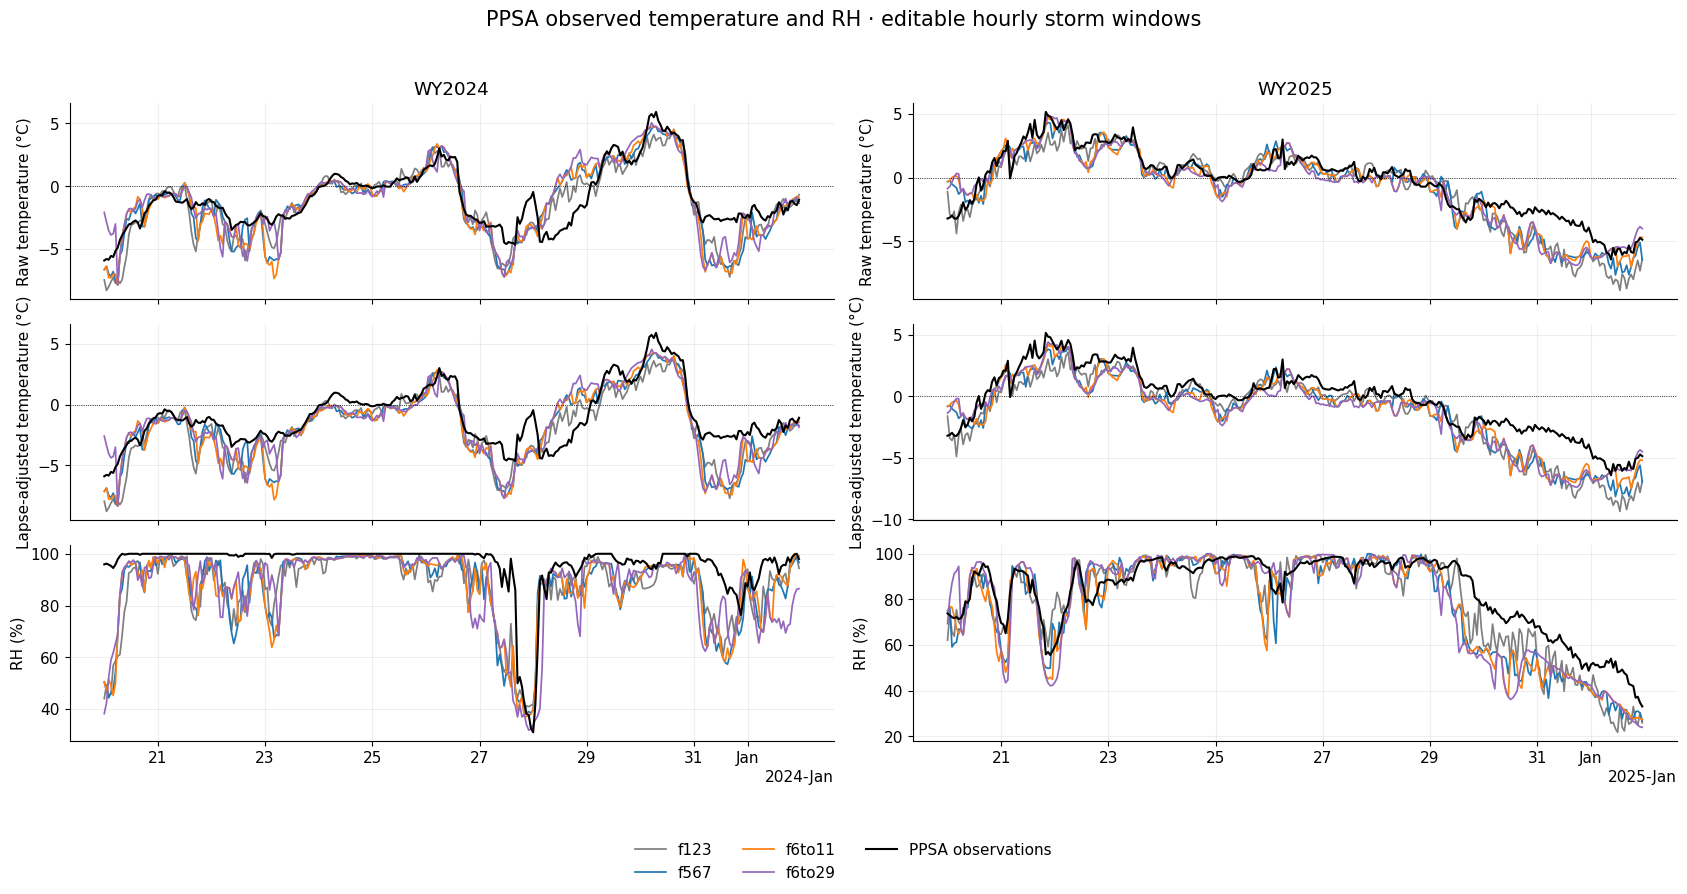

In [6]:
station_rows=[]
for period in PERIODS:
    for variable in ['TA','TA_lapse','RH','PSUM']:
        table=fc.common_table(frames,period,variable,observations=observations)
        station_rows.append(fc.metrics(table,'PPSA',variable).assign(period=period,variable=variable))
station_metrics=pd.concat(station_rows,ignore_index=True)
display(station_metrics[['period','variable','option','n_hours','bias','MAE','RMSE',
    'reference_total_mm','option_total_mm']].round(3))
# Dedicated station temperature/RH view over the editable hourly windows.
fig,axes=plt.subplots(3,2,figsize=(17,9),sharex='col')
for col,period in enumerate(PERIODS):
    window=ZOOM_WINDOWS[period]
    for row,variable in enumerate(['TA','TA_lapse','RH']):
        ax=axes[row,col]
        for option in OPTIONS:
            s=frames[(period,option)][variable].loc[window[0]:window[1]]
            ax.plot(s.index,s,**STYLES[option])
        obsvar='TA' if variable=='TA_lapse' else variable
        s=observations[obsvar].loc[window[0]:window[1]]
        ax.plot(s.index,s,color='black',lw=1.5)
        ax.set_ylabel({'TA':'Raw temperature (°C)','TA_lapse':'Lapse-adjusted temperature (°C)','RH':'RH (%)'}[variable])
        if row==0:ax.set_title(period)
        if row<2:ax.axhline(0,color='black',lw=.6,ls=':')
        date_axis(ax)
fig.suptitle('PPSA observed temperature and RH · editable hourly storm windows',fontsize=15)
fig.legend(handles=legend_handles(PERIODS[-1]),loc='lower center',ncol=3,frameon=False)
fig.tight_layout(rect=(0,.10,1,.96));plt.show()

## Precipitation totals on identical observed hours

Cumulative curves below include only timestamps where **every selected forecast option and the PPSA hourly increment are valid**. All curves start from zero at the shared comparison window’s start. Excluded hours are shown as gaps; later points resume the running sum of matched hours. These are **matched-hour totals**, not complete water-year or continuously observed storm totals. The coverage table states how many hours are included. No missing precipitation is filled with zero, and no comparison uses different samples for different curves.

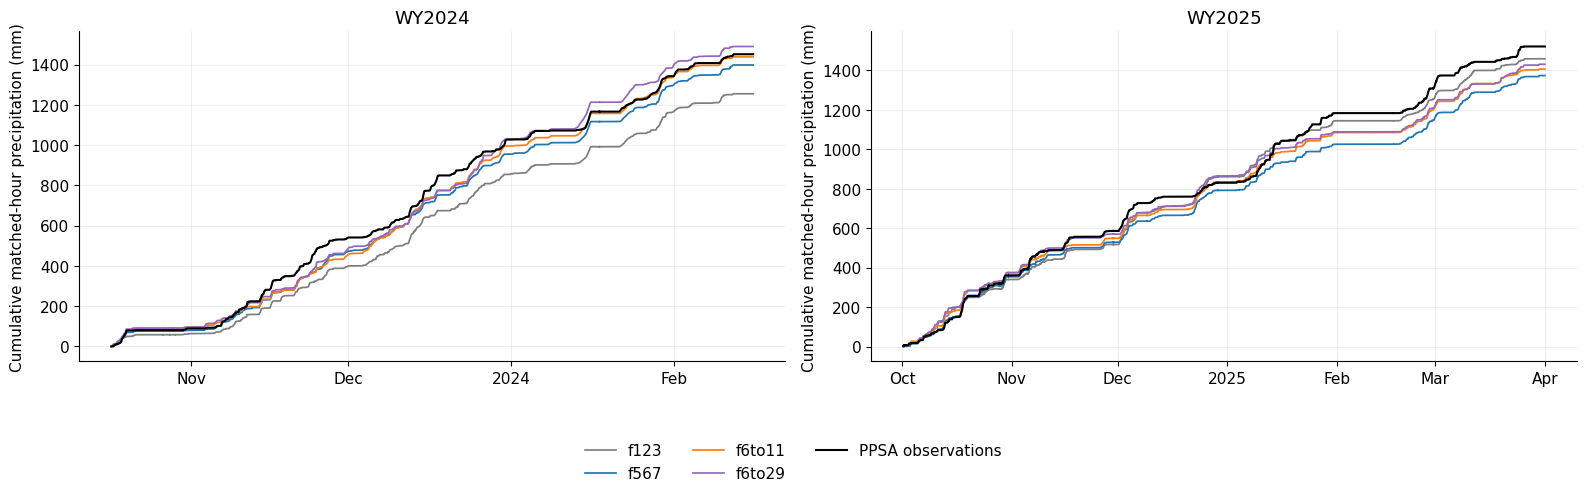

,period,start_UTC,end_UTC,possible_hours,matched_hours,excluded_hours
0,WY2024,2023-10-01 06:00:00,2024-02-16 04:00:00,3311,2932,379
1,WY2025,2024-10-01 06:00:00,2025-04-01 00:00:00,4363,4294,69


In [7]:
fig,axes=plt.subplots(1,2,figsize=(16,5))
precip_coverage=[]
for period,ax in zip(PERIODS,axes):
    table=fc.common_table(frames,period,'PSUM',observations=observations)
    start=max(frames[(period,o)].index.min() for o in OPTIONS)
    end=min(frames[(period,o)].index.max() for o in OPTIONS)
    table=table.loc[start:end]
    valid=table.notna().all(axis=1)
    totals=table.loc[valid].cumsum().reindex(table.index)
    for option in OPTIONS:ax.plot(totals.index,totals[option],**STYLES[option])
    ax.plot(totals.index,totals.PPSA,color='black',lw=1.5)
    ax.set(title=period,ylabel='Cumulative matched-hour precipitation (mm)');date_axis(ax)
    precip_coverage.append(dict(period=period,start_UTC=start,end_UTC=end,
        possible_hours=len(table),matched_hours=int(valid.sum()),excluded_hours=int((~valid).sum())))
fig.legend(handles=legend_handles(PERIODS[-1]),loc='lower center',ncol=3,frameon=False)
fig.tight_layout(rect=(0,.18,1,1));plt.show()
display(pd.DataFrame(precip_coverage))

## Reading the results

Use the lead schedule and coverage audit before attributing changes to forecast length. In particular, the WY2025 file labeled f678 is a 5–7-hour series with different gaps, so it does not test an independent 6–8-hour forecast recipe. The f6to11-versus-f567 diagnostics isolate the requested mosaic difference over a larger matched window than the all-option station comparison.

Compare raw and lapse-adjusted temperature errors separately, and evaluate RH and precipitation on their own units and valid-hour counts. PRATE-derived precipitation is retained to match the existing snow-model forcing convention; determining whether interval-accumulated GRIB precipitation performs better would require a separate interval-aware reconstruction, preserving initialization and accumulation bounds.

All figures display inline. This notebook reads the source files and does not change downloads, processed NetCDFs, station observations, or simulation inputs. Diagnostic exports, if wanted, belong in the repository’s ignored `temporary/forecast_comparison/` directory.